In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Load the dataset
df = pd.read_csv('customer_shopping_data.csv')

# Initial inspection
print("Dataset Shape:", df.shape)
print("\nData Types:\n", df.dtypes)
print("\nNull Values:\n", df.isnull().sum())

Dataset Shape: (99457, 10)

Data Types:
 invoice_no            str
customer_id           str
gender                str
age                 int64
category              str
quantity            int64
price             float64
payment_method        str
invoice_date          str
shopping_mall         str
dtype: object

Null Values:
 invoice_no        0
customer_id       0
gender            0
age               0
category          0
quantity          0
price             0
payment_method    0
invoice_date      0
shopping_mall     0
dtype: int64


In [7]:
print(df.columns.tolist())

['invoice_no', 'customer_id', 'gender', 'age', 'category', 'quantity', 'price', 'payment_method', 'invoice_date', 'shopping_mall']


In [8]:
# Create total amount for each transaction
df['total_amount'] = df['quantity'] * df['price']

# Numerical columns
numerical_columns = ['age', 'quantity', 'price', 'total_amount']

stats = pd.DataFrame({
    'Mean': df[numerical_columns].mean(),
    'Median': df[numerical_columns].median(),
    'Mode': df[numerical_columns].mode().iloc[0],
    'Standard Deviation': df[numerical_columns].std()
})

stats

,Mean,Median,Mode,Standard Deviation
age,43.427089,43.00,37.00,14.990054
quantity,3.003429,3.00,3.00,1.413025
price,689.256321,203.30,600.16,941.184567
total_amount,2528.789268,600.17,1200.32,4222.475781


## Descriptive Statistics Observation

The descriptive statistics provide an overview of customer age, quantity purchased, product price, and total transaction value. The results help identify the typical customer profile and the general spending behaviour within the dataset.

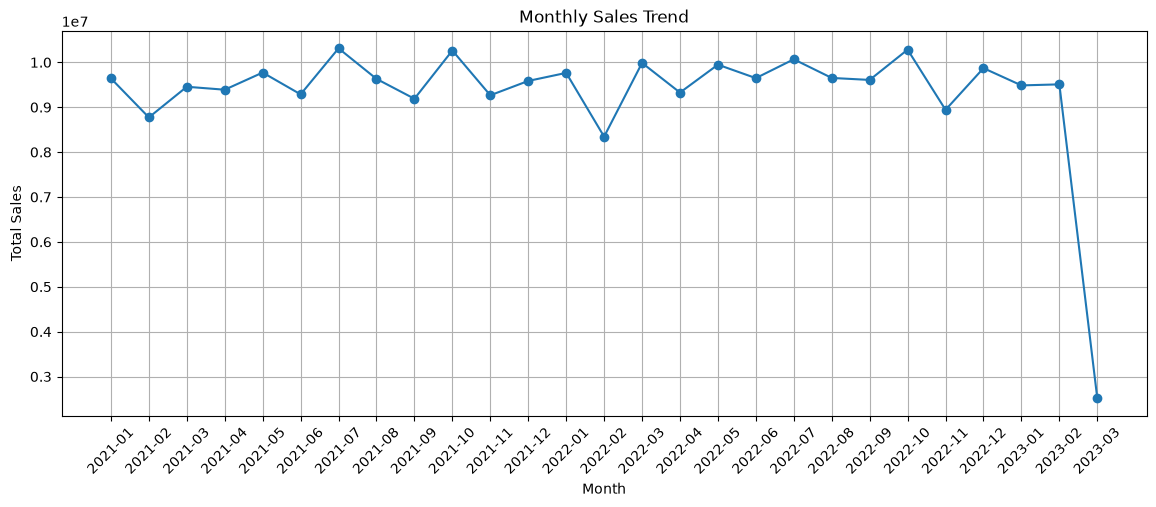

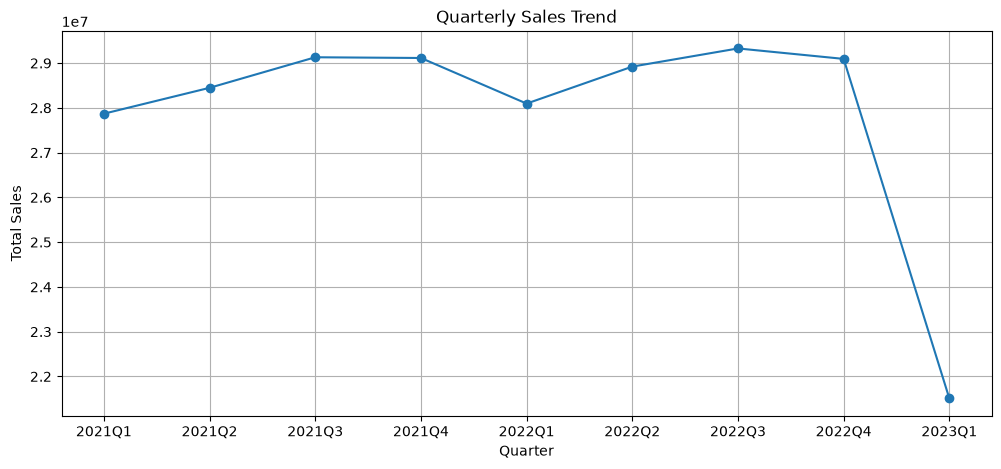

In [9]:
# Convert invoice_date to datetime
df['invoice_date'] = pd.to_datetime(
    df['invoice_date'],
    dayfirst=True,
    errors='coerce'
)

# Extract Month and Quarter
df['month_year'] = df['invoice_date'].dt.to_period('M')
df['quarter'] = df['invoice_date'].dt.to_period('Q')

# Aggregate total sales
monthly_sales = df.groupby('month_year')['total_amount'].sum()
quarterly_sales = df.groupby('quarter')['total_amount'].sum()

# Monthly Sales Trend
plt.figure(figsize=(14, 5))
plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker='o'
)

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

# Quarterly Sales Trend
plt.figure(figsize=(12, 5))
plt.plot(
    quarterly_sales.index.astype(str),
    quarterly_sales.values,
    marker='o'
)

plt.title('Quarterly Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.grid(True)
plt.show()

### Monthly Sales Trend Observation

Monthly sales fluctuate over time, with some months recording noticeably higher sales than others. This indicates that customer spending is not completely constant throughout the year and may be influenced by seasonal shopping patterns.

### Quarterly Sales Trend Observation

Quarterly sales also show variations across the year. Certain quarters generate stronger revenue than others, which suggests that the business could use seasonal sales patterns when planning inventory, promotions, and marketing activities.

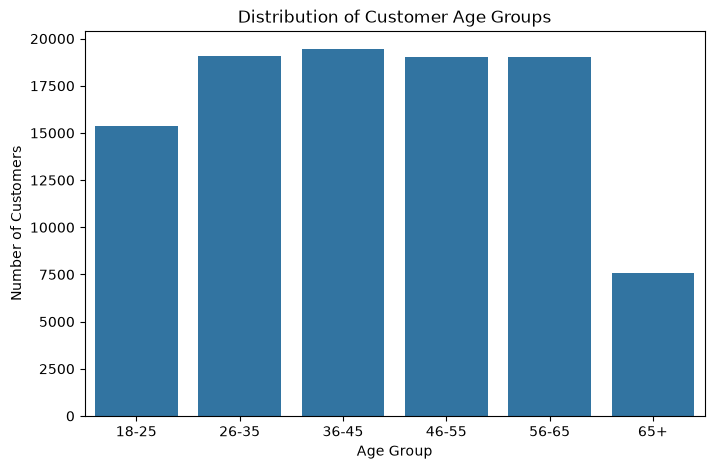

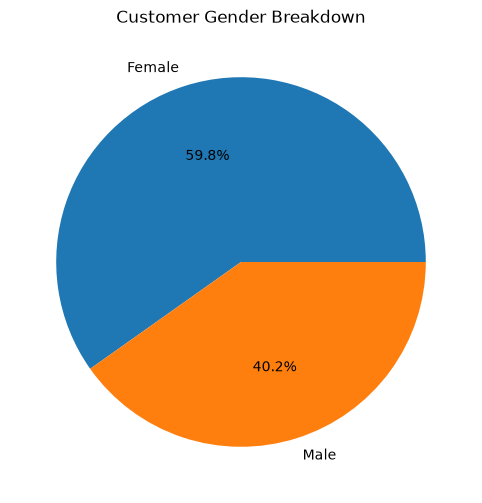

In [10]:
# Create customer-level dataset
customers = df.drop_duplicates(subset='customer_id').copy()

# Age Group Distribution
bins = [18, 26, 36, 46, 56, 66, 100]
labels = ['18-25', '26-35', '36-45', '46-55', '56-65', '65+']

customers['age_group'] = pd.cut(
    customers['age'],
    bins=bins,
    labels=labels,
    right=False
)

plt.figure(figsize=(8, 5))
sns.countplot(data=customers, x='age_group')
plt.title('Distribution of Customer Age Groups')
plt.xlabel('Age Group')
plt.ylabel('Number of Customers')
plt.show()

# Gender Breakdown
plt.figure(figsize=(6, 6))
customers['gender'].value_counts().plot.pie(
    autopct='%1.1f%%'
)

plt.title('Customer Gender Breakdown')
plt.ylabel('')
plt.show()

### Age Group Observation

Customers are distributed across different age groups, showing that the business attracts shoppers from a wide age range. Some age groups have a larger customer presence and may therefore represent important target segments for marketing campaigns.

### Gender Observation

The gender distribution shows the proportion of male and female customers in the dataset. Understanding this distribution can help the business design promotions and product campaigns that better reflect its customer base.

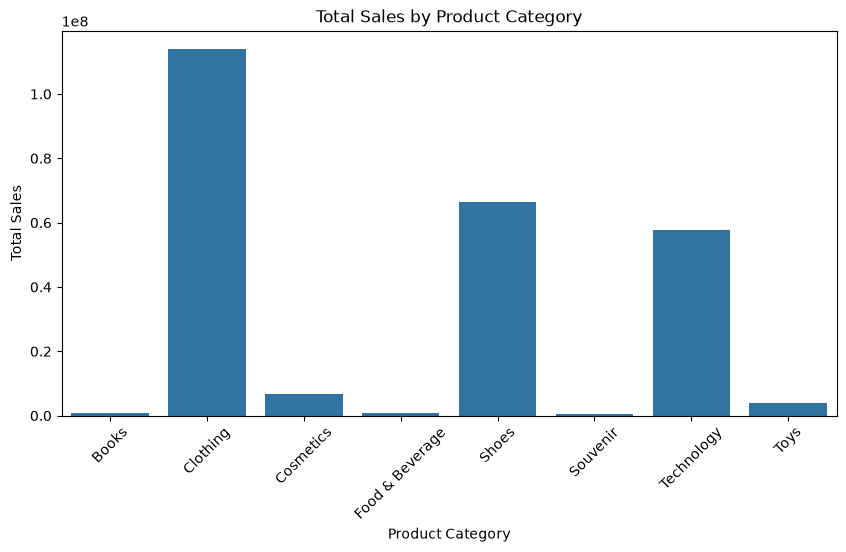

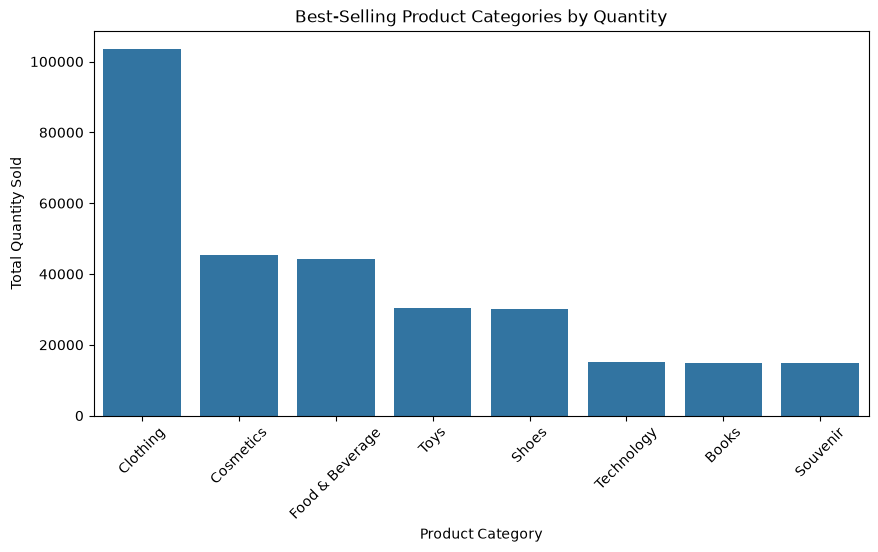

In [11]:
# Revenue by Product Category
category_sales = df.groupby('category')['total_amount'].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=category_sales, x='category', y='total_amount')

plt.title('Total Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.show()


# Best-Selling Product Categories by Quantity
top_categories = df.groupby('category')['quantity'].sum().reset_index()
top_categories = top_categories.sort_values('quantity', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=top_categories, x='category', y='quantity')

plt.title('Best-Selling Product Categories by Quantity')
plt.xlabel('Product Category')
plt.ylabel('Total Quantity Sold')
plt.xticks(rotation=45)
plt.show()

### Product Category Revenue Observation

Revenue differs considerably across product categories. Some categories contribute much more to total sales than others, making them particularly important to the overall performance of the retail business.

In [12]:
top_categories = (
    df.groupby('category')['quantity']
      .sum()
      .sort_values(ascending=False)
)

top_categories

category
Clothing           103558
Cosmetics           45465
Food & Beverage     44277
Toys                30321
Shoes               30217
Technology          15021
Books               14982
Souvenir            14871
Name: quantity, dtype: int64

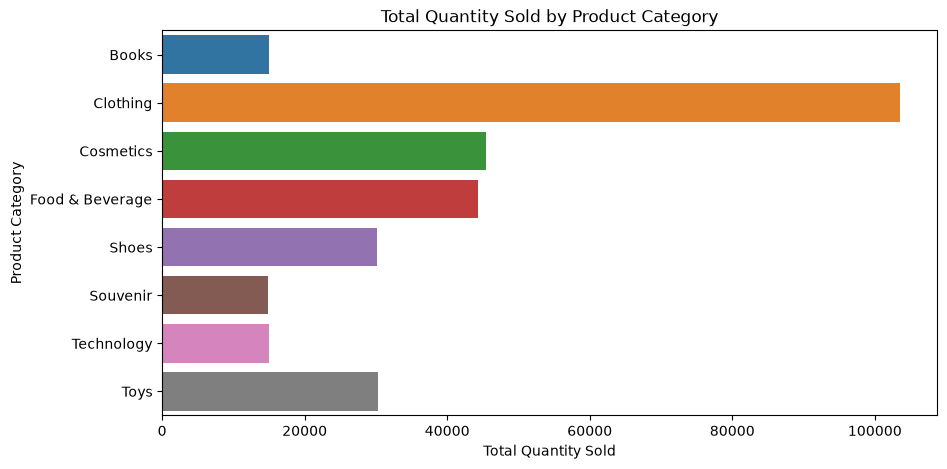

In [13]:
top_products = df.groupby('category')['quantity'].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(
    data=top_products,
    x='quantity',
    y='category',
    hue='category',
    legend=False
)

plt.title('Total Quantity Sold by Product Category')
plt.xlabel('Total Quantity Sold')
plt.ylabel('Product Category')
plt.show()

### Best-Selling Category Observation

The quantity analysis shows which product categories are purchased most frequently. Categories with high quantities sold represent products with stronger customer demand and should receive greater attention when managing inventory.

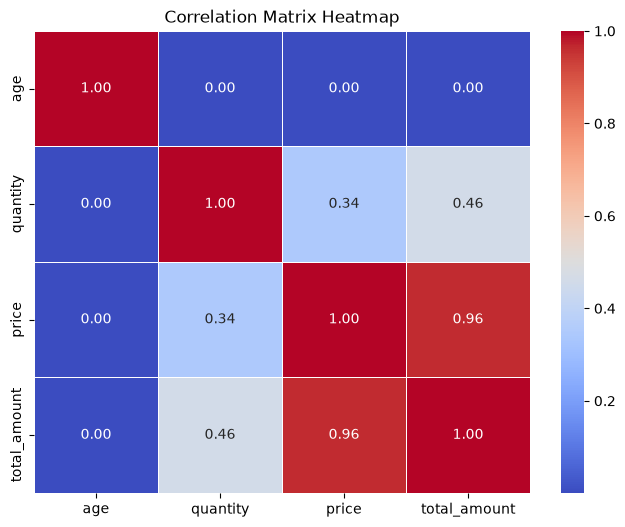

In [14]:
# Select meaningful numerical columns
numerical_df = df[['age', 'quantity', 'price', 'total_amount']]

# Calculate correlation matrix
corr_matrix = numerical_df.corr()

# Plot heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix Heatmap')
plt.show()

### Correlation Observation

The correlation heatmap shows the relationships between age, quantity, price, and total amount spent. Total transaction value is naturally influenced by both the quantity purchased and the price of the items, while customer age is expected to have a weaker relationship with transaction value.

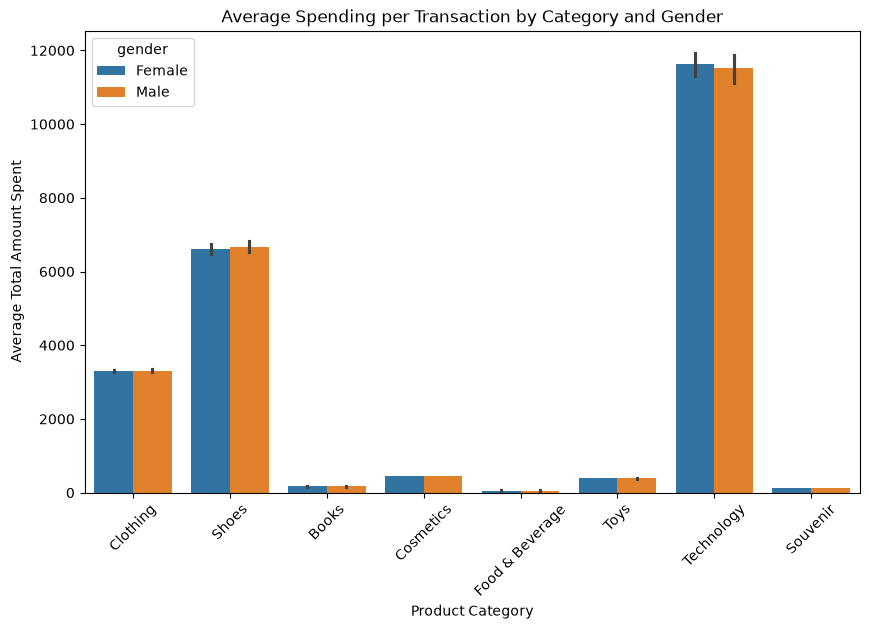

In [15]:
# Set the figure size
plt.figure(figsize=(10, 6))

# Plot average spending by category, split by gender
sns.barplot(
    data=df,
    x='category',
    y='total_amount',
    hue='gender'
)

# Add titles and labels
plt.title('Average Spending per Transaction by Category and Gender')
plt.xlabel('Product Category')
plt.ylabel('Average Total Amount Spent')

plt.xticks(rotation=45)
plt.show()

### Additional Visualization Observation

Average spending varies across product categories and between male and female customers. This reveals that purchasing behaviour may differ by both gender and product category, which can help the business create more targeted marketing strategies.

## Conclusion and Recommendations

Based on the exploratory analysis, the following recommendations can be made:

1. The business should maintain sufficient inventory for the product categories with the highest sales and quantity purchased to reduce the risk of stock shortages.

2. Marketing campaigns and promotional offers should be planned around periods with weaker monthly or quarterly sales in order to encourage additional customer spending.

3. Customer demographics and gender-based purchasing patterns can be used to develop more targeted promotions for specific product categories and customer groups.